# Step 4:
Frozen-feature probes on the group-aware split (train-only centring). Nothing is ever fitted on test rows.

In [1]:
import json, random, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             normalized_mutual_info_score, adjusted_rand_score, confusion_matrix)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier

from utils import load, load_split_data, get_split, COLOR_I, COLOR_T, COLOR_IT

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

D = load_split_data()
_, _, groups_all = get_split()
Y_tr, Y_te = D["Y_tr"], D["Y_te"]
g_tr = groups_all[D["train_idx"]]
print("train", len(Y_tr), "test", len(Y_te), "classes", len(np.unique(Y_tr)))

FEATS = {
    "I": (D["I_tr"], D["I_te"]),
    "T": (D["T_tr"], D["T_te"]),
    "I+T": (np.hstack([D["I_tr"], D["T_tr"]]), np.hstack([D["I_te"], D["T_te"]])),
}
COLORS = {"I": COLOR_I, "T": COLOR_T, "I+T": COLOR_IT}
classes = np.unique(Y_tr)
summary = {}

def make_lr(C):
    return LogisticRegression(C=C, max_iter=5000)

train 2005 test 495 classes 31


## 1. Baselines

In [2]:
vals, cnts = np.unique(Y_tr, return_counts=True)
maj = vals[np.argmax(cnts)]
maj_acc = float(np.mean(Y_te == maj))
print(f"majority class {maj}: test acc {maj_acc:.4f}")
summary["majority_acc"] = round(maj_acc, 4)
summary["majority_class"] = int(maj)

majority class 34: test acc 0.0626


The shuffled-label control uses the C chosen in step 2 below, so it is run after the C selection.

## 2. Linear probe (main result)
C chosen by 5-fold StratifiedGroupKFold on the train set only.

In [3]:
CS = [0.01, 0.1, 1, 10, 100]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(np.zeros(len(Y_tr)), Y_tr, g_tr))

cv_scores, best_C = {}, {}
for name, (Xtr, Xte) in FEATS.items():
    cv_scores[name] = {}
    for C in CS:
        accs = [accuracy_score(Y_tr[va], make_lr(C).fit(Xtr[tr], Y_tr[tr]).predict(Xtr[va])) for tr, va in folds]
        cv_scores[name][C] = float(np.mean(accs))
    best_C[name] = max(CS, key=lambda c: (cv_scores[name][c], -c))  # tie -> smaller C
    print(name, {c: round(v, 4) for c, v in cv_scores[name].items()}, "-> C =", best_C[name])

I {0.01: 0.1745, 0.1: 0.7545, 1: 0.9279, 10: 0.9508, 100: 0.9505} -> C = 10


T {0.01: 0.1188, 0.1: 0.6357, 1: 0.8328, 10: 0.8694, 100: 0.8676} -> C = 10


I+T {0.01: 0.3365, 0.1: 0.8919, 1: 0.9699, 10: 0.9753, 100: 0.9758} -> C = 100


In [4]:
rng = np.random.default_rng(SEED)
probe, pred = {}, {}
for name, (Xtr, Xte) in FEATS.items():
    clf = make_lr(best_C[name]).fit(Xtr, Y_tr)
    p = clf.predict(Xte); pred[name] = p
    correct = (p == Y_te).astype(float)
    boots = np.array([correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(1000)])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    probe[name] = dict(C=best_C[name], acc=float(correct.mean()),
                       bal_acc=float(balanced_accuracy_score(Y_te, p)),
                       macro_f1=float(f1_score(Y_te, p, average="macro")),
                       ci_lo=float(lo), ci_hi=float(hi))
    r = probe[name]
    print(f"{name:4s} C={r['C']:<5} acc={r['acc']:.4f} [{lo:.4f}, {hi:.4f}]  bal_acc={r['bal_acc']:.4f}  macro_F1={r['macro_f1']:.4f}")

assert probe["I+T"]["acc"] > probe["I"]["acc"] > probe["T"]["acc"], "Expected order I+T > I > T does not hold"
print("order I+T > I > T holds")

I    C=10    acc=0.9253 [0.9010, 0.9475]  bal_acc=0.9282  macro_F1=0.9233
T    C=10    acc=0.8646 [0.8343, 0.8930]  bal_acc=0.8642  macro_F1=0.8574


I+T  C=100   acc=0.9636 [0.9475, 0.9798]  bal_acc=0.9622  macro_F1=0.9597
order I+T > I > T holds


In [5]:
# shuffled-label control: permute TRAIN labels, evaluate on true test labels
shuf = {}
perm = np.random.default_rng(SEED).permutation(len(Y_tr))
for name, (Xtr, Xte) in FEATS.items():
    shuf[name] = float(accuracy_score(Y_te, make_lr(best_C[name]).fit(Xtr, Y_tr[perm]).predict(Xte)))
    print(f"shuffled-label control {name}: {shuf[name]:.4f}  (chance ~ {1/len(classes):.3f})")

shuffled-label control I: 0.0364  (chance ~ 0.032)


shuffled-label control T: 0.0384  (chance ~ 0.032)


shuffled-label control I+T: 0.0283  (chance ~ 0.032)


## 3. k-NN (cosine)

In [6]:
KS = [1, 5, 10, 20]
knn = {}
for name, (Xtr, Xte) in FEATS.items():
    knn[name] = {k: float(accuracy_score(Y_te, KNeighborsClassifier(n_neighbors=k, metric="cosine").fit(Xtr, Y_tr).predict(Xte))) for k in KS}
    print(name, {k: round(v, 4) for k, v in knn[name].items()})

I {1: 0.8788, 5: 0.903, 10: 0.901, 20: 0.899}
T {1: 0.7657, 5: 0.7818, 10: 0.7495, 20: 0.699}


I+T {1: 0.901, 5: 0.9232, 10: 0.9192, 20: 0.9192}


## 4. Label efficiency
n labelled train samples per class (fewer if a class is smaller), 10 repeats, C from step 2.

In [7]:
NS = [1, 2, 5, 10, 20, "all"]
N_REP = 10
cls_idx = {c: np.flatnonzero(Y_tr == c) for c in classes}
max_cls = max(len(v) for v in cls_idx.values())
eff = {name: {} for name in FEATS}
for name, (Xtr, Xte) in FEATS.items():
    for n in NS:
        accs = []
        for rep in range(N_REP):
            r = np.random.default_rng(SEED + rep)
            idx = np.concatenate([v if n == "all" else r.choice(v, min(n, len(v)), replace=False) for v in cls_idx.values()])
            accs.append(accuracy_score(Y_te, make_lr(best_C[name]).fit(Xtr[idx], Y_tr[idx]).predict(Xte)))
        eff[name][str(n)] = (float(np.mean(accs)), float(np.std(accs)))
    print(name, {n: f"{m:.3f}±{s:.3f}" for n, (m, s) in eff[name].items()})
print("max train samples in a class:", max_cls)

I {'1': '0.604±0.040', '2': '0.719±0.022', '5': '0.842±0.016', '10': '0.883±0.007', '20': '0.908±0.005', 'all': '0.925±0.000'}


T {'1': '0.447±0.039', '2': '0.572±0.040', '5': '0.734±0.018', '10': '0.808±0.013', '20': '0.836±0.007', 'all': '0.865±0.000'}


I+T {'1': '0.656±0.025', '2': '0.789±0.031', '5': '0.895±0.018', '10': '0.936±0.007', '20': '0.954±0.007', 'all': '0.964±0.000'}
max train samples in a class: 119


## 5. Unsupervised clustering (all 2500 rows, no labels for fitting)

In [8]:
I_all, T_all, Y_all = load()
tr_idx = D["train_idx"]
# same train-mean preprocessing as the split data, applied to all rows
def prep(X, mean):
    X = X - mean
    return X / np.linalg.norm(X, axis=1, keepdims=True)
Ia, Ta = prep(I_all, D["I_mean"]), prep(T_all, D["T_mean"])
ALL = {"I": Ia, "T": Ta, "I+T": np.hstack([Ia, Ta])}
km = {}
for name, X in ALL.items():
    lab = KMeans(n_clusters=31, n_init=10, random_state=SEED).fit_predict(X)
    km[name] = dict(nmi=float(normalized_mutual_info_score(Y_all, lab)), ari=float(adjusted_rand_score(Y_all, lab)))
    print(f"{name:4s} NMI={km[name]['nmi']:.4f} ARI={km[name]['ari']:.4f}")

I    NMI=0.7823 ARI=0.6218


T    NMI=0.5467 ARI=0.3189


I+T  NMI=0.8044 ARI=0.6341


## 6. Error analysis

In [9]:
per_class, worst5 = {}, {}
for name in FEATS:
    rows = []
    for c in classes:
        m = Y_te == c
        if m.sum():
            rows.append((int(c), float((pred[name][m] == c).mean()), int(m.sum())))
    per_class[name] = {c: (a, n) for c, a, n in rows}
    worst5[name] = sorted(rows, key=lambda r: (r[1], r[0]))[:5]
    print(f"{name}: 5 worst classes (class, acc, n_test)")
    for c, a, n in worst5[name]:
        print(f"   class {c:>2}: acc={a:.3f}  n_test={n}")
print("classes with no test rows:", [int(c) for c in classes if (Y_te == c).sum() == 0])

I: 5 worst classes (class, acc, n_test)
   class 23: acc=0.615  n_test=13
   class 27: acc=0.688  n_test=16
   class 28: acc=0.769  n_test=13
   class  6: acc=0.786  n_test=14
   class 25: acc=0.833  n_test=18
T: 5 worst classes (class, acc, n_test)
   class  9: acc=0.583  n_test=12
   class 23: acc=0.615  n_test=13
   class 26: acc=0.667  n_test=18
   class 30: acc=0.706  n_test=17
   class  6: acc=0.714  n_test=14
I+T: 5 worst classes (class, acc, n_test)
   class 23: acc=0.769  n_test=13
   class 29: acc=0.818  n_test=11
   class  9: acc=0.833  n_test=12
   class  3: acc=0.889  n_test=18
   class 24: acc=0.895  n_test=19
classes with no test rows: []


In [10]:
labs = list(classes)
cm = confusion_matrix(Y_te, pred["I"], labels=labs)
cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
off = [(int(labs[i]), int(labs[j]), int(cm[i, j]), float(cm_norm[i, j])) for i in range(len(labs)) for j in range(len(labs)) if i != j and cm[i, j] > 0]
top_conf = sorted(off, key=lambda r: (-r[2], -r[3]))[:5]
print("top-5 confusions for I (true -> pred, count, row fraction):")
for t, p, n, f in top_conf:
    print(f"   {t} -> {p}: {n}  ({f:.2f} of class {t} test rows)")

# silhouette-hard classes from step 2
for name in FEATS:
    order = [c for c, _, _ in sorted(((c, a, n) for c, (a, n) in per_class[name].items()), key=lambda r: (r[1], r[0]))]
    print(name, "rank by accuracy (1 = worst):", {c: (order.index(c) + 1 if c in order else None) for c in (25, 2, 13)},
          "| acc:", {c: (round(per_class[name][c][0], 3), per_class[name][c][1]) for c in (25, 2, 13) if c in per_class[name]})

okI, okT = pred["I"] == Y_te, pred["T"] == Y_te
comp = dict(I_right_T_wrong=int((okI & ~okT).sum()), T_right_I_wrong=int((~okI & okT).sum()),
            both_right=int((okI & okT).sum()), both_wrong=int((~okI & ~okT).sum()))
print("complementarity:", comp)

top-5 confusions for I (true -> pred, count, row fraction):
   27 -> 17: 3  (0.19 of class 27 test rows)
   23 -> 7: 2  (0.15 of class 23 test rows)
   23 -> 17: 2  (0.15 of class 23 test rows)
   28 -> 6: 2  (0.15 of class 28 test rows)
   6 -> 25: 2  (0.14 of class 6 test rows)
I rank by accuracy (1 = worst): {25: 5, 2: 11, 13: 21} | acc: {25: (0.833, 18), 2: (0.917, 12), 13: (1.0, 15)}
T rank by accuracy (1 = worst): {25: 7, 2: 20, 13: 15} | acc: {25: (0.778, 18), 2: (0.917, 12), 13: (0.867, 15)}
I+T rank by accuracy (1 = worst): {25: 29, 2: 12, 13: 19} | acc: {25: (1.0, 18), 2: (1.0, 12), 13: (1.0, 15)}
complementarity: {'I_right_T_wrong': 61, 'T_right_I_wrong': 31, 'both_right': 397, 'both_wrong': 6}


## 7. Fig 3

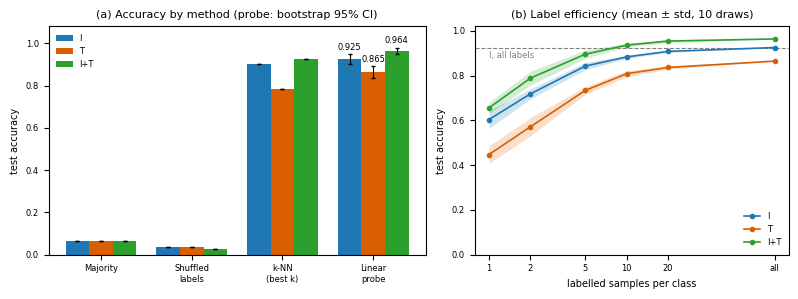

In [11]:
RC = {"font.size": 7, "axes.titlesize": 8, "xtick.labelsize": 6, "ytick.labelsize": 6,
      "axes.labelsize": 7, "legend.fontsize": 6}
best_k = {n: max(KS, key=lambda k: knn[n][k]) for n in FEATS}
Path("../figures").mkdir(exist_ok=True)
with plt.rc_context(RC):
    fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3), gridspec_kw={"width_ratios": [1.2, 1]})
    methods = ["Majority", "Shuffled\nlabels", "k-NN\n(best k)", "Linear\nprobe"]
    w = 0.26
    for i, name in enumerate(FEATS):
        v = [maj_acc, shuf[name], knn[name][best_k[name]], probe[name]["acc"]]
        x = np.arange(4) + (i - 1) * w
        err = np.zeros((2, 4)); err[0, 3] = probe[name]["acc"] - probe[name]["ci_lo"]; err[1, 3] = probe[name]["ci_hi"] - probe[name]["acc"]
        a.bar(x, v, w, color=COLORS[name], label=name, yerr=err, error_kw=dict(lw=0.8, capsize=1.5))
        a.text(x[3], probe[name]["ci_hi"] + 0.01, f"{probe[name]['acc']:.3f}", ha="center", va="bottom", fontsize=6)
    a.set_xticks(np.arange(4)); a.set_xticklabels(methods)
    a.set_ylabel("test accuracy"); a.set_ylim(0, 1.08); a.legend(frameon=False, loc="upper left")
    a.set_title("(a) Accuracy by method (probe: bootstrap 95% CI)")

    xpos = [1, 2, 5, 10, 20, max(max_cls, 21)]
    for name in FEATS:
        m = np.array([eff[name][str(n)][0] for n in NS]); s = np.array([eff[name][str(n)][1] for n in NS])
        b.plot(xpos, m, "-o", ms=3, lw=1.2, color=COLORS[name], label=name)
        b.fill_between(xpos, m - s, m + s, color=COLORS[name], alpha=0.2, lw=0)
    b.axhline(probe["I"]["acc"], color="grey", ls="--", lw=0.8, zorder=0)
    b.text(1.0, probe["I"]["acc"] - 0.015, "I, all labels", color="grey", fontsize=6, va="top", ha="left")
    b.set_xscale("log"); b.set_xticks(xpos); b.set_xticklabels(["1", "2", "5", "10", "20", "all"])
    b.minorticks_off()
    b.set_xlabel("labelled samples per class"); b.set_ylabel("test accuracy"); b.set_ylim(0, 1.02)
    b.set_title("(b) Label efficiency (mean ± std, 10 draws)"); b.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    fig.savefig("../figures/fig3_probes.pdf", bbox_inches="tight")
    fig.savefig("../figures/fig3_probes.png", dpi=200, bbox_inches="tight")
    plt.show()

## 8. Summary

In [12]:
summary.update({
    "chosen_C": {n: best_C[n] for n in FEATS},
    "cv_accuracy": {n: {str(c): round(v, 4) for c, v in cv_scores[n].items()} for n in FEATS},
    "probe": {n: {k: round(v, 4) if isinstance(v, float) else v for k, v in probe[n].items()} for n in FEATS},
    "shuffled_label_acc": {n: round(v, 4) for n, v in shuf.items()},
    "knn_acc": {n: {str(k): round(v, 4) for k, v in knn[n].items()} for n in FEATS},
    "label_efficiency": {n: {k: {"mean": round(m, 4), "std": round(s, 4)} for k, (m, s) in eff[n].items()} for n in FEATS},
    "kmeans": {n: {k: round(v, 4) for k, v in km[n].items()} for n in FEATS},
    "worst5_classes": {n: [{"class": c, "acc": round(a, 4), "n_test": k} for c, a, k in worst5[n]] for n in FEATS},
    "top5_confusions_I": [{"true": t, "pred": p, "count": n, "frac_of_true_class": round(f, 4)} for t, p, n, f in top_conf],
    "complementarity": comp,
})
Path("../results").mkdir(exist_ok=True)
with open("../results/step4_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "majority_acc": 0.0626,
  "majority_class": 34,
  "chosen_C": {
    "I": 10,
    "T": 10,
    "I+T": 100
  },
  "cv_accuracy": {
    "I": {
      "0.01": 0.1745,
      "0.1": 0.7545,
      "1": 0.9279,
      "10": 0.9508,
      "100": 0.9505
    },
    "T": {
      "0.01": 0.1188,
      "0.1": 0.6357,
      "1": 0.8328,
      "10": 0.8694,
      "100": 0.8676
    },
    "I+T": {
      "0.01": 0.3365,
      "0.1": 0.8919,
      "1": 0.9699,
      "10": 0.9753,
      "100": 0.9758
    }
  },
  "probe": {
    "I": {
      "C": 10,
      "acc": 0.9253,
      "bal_acc": 0.9282,
      "macro_f1": 0.9233,
      "ci_lo": 0.901,
      "ci_hi": 0.9475
    },
    "T": {
      "C": 10,
      "acc": 0.8646,
      "bal_acc": 0.8642,
      "macro_f1": 0.8574,
      "ci_lo": 0.8343,
      "ci_hi": 0.893
    },
    "I+T": {
      "C": 100,
      "acc": 0.9636,
      "bal_acc": 0.9622,
      "macro_f1": 0.9597,
      "ci_lo": 0.9475,
      "ci_hi": 0.9798
    }
  },
  "shuffled_label_acc": {
    "I"